# COVID19 Reinfection Health Analysis

**Introduction**

In this notebook,We make a comprehensive analysis of the COVID-19 reinfection and health dataset. Our goal is to explore correlations between patient characteristics, comorbidities, and outcomes, with an optional predictive model to forecast the likelihood of reinfection based on available features. We incorporate a variety of visualizations, from box plots to heatmaps, to ensure a holistic assessment of the dataset.

**Importing Libraries**

In [19]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from datetime import datetime

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, auc
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

import warnings
warnings.filterwarnings('ignore')

**Uploading Data**

In [2]:
df = pd.read_csv('covid_related_disease_data.csv')
df.head()

,Patient_ID,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,...,Reinfection,Date_of_Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,1,69,Male,Hovedstaden,Obesity,2022-06-21,Delta,Mild,Moderate,Yes,...,No,NaN,Yes,NaN,1,2022-09-22,NaN,Healthcare,Never,27.7
1,2,38,Male,Sjælland,Asthma,2024-02-02,XBB.1.5,Mild,Moderate,No,...,No,NaN,No,NaN,0,NaN,NaN,Healthcare,Never,21.9
2,3,41,Female,Syddanmark,Hypertension,2023-05-28,Beta,Mild,High,Yes,...,No,NaN,Yes,Janssen,3,2024-05-14,NaN,Unemployed,Never,22.7
3,4,81,Female,Hovedstaden,Asthma,2023-08-13,Delta,Severe,High,No,...,Yes,2024-08-24,Yes,AstraZeneca,1,2024-10-31,NaN,Office Worker,Never,27.7
4,5,50,Female,Syddanmark,Cardiovascular,2023-03-10,Delta,Mild,High,No,...,No,NaN,Yes,NaN,2,2023-07-05,NaN,Student,Never,11.9


In [3]:
df.shape

(3000, 26)

In [4]:
print('Data loaded successfully. The dataframe has {} rows and {} columns.'.format(df.shape[0], df.shape[1]))

Data loaded successfully. The dataframe has 3000 rows and 26 columns.


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Patient_ID               3000 non-null   int64  
 1   Age                      3000 non-null   int64  
 2   Gender                   3000 non-null   object 
 3   Region                   3000 non-null   object 
 4   Preexisting_Condition    2531 non-null   object 
 5   Date_of_Infection        3000 non-null   object 
 6   COVID_Strain             3000 non-null   object 
 7   Symptoms                 3000 non-null   object 
 8   Severity                 3000 non-null   object 
 9   Hospitalized             3000 non-null   object 
 10  Hospital_Admission_Date  876 non-null    object 
 11  Hospital_Discharge_Date  876 non-null    object 
 12  ICU_Admission            3000 non-null   object 
 13  Ventilator_Support       3000 non-null   object 
 14  Recovered               

In [6]:
# the info func shows the names of features and their data types

In [7]:
#data cleaning

In [8]:
# Convert date columns from string to datetime
date_columns = ['Date_of_Infection', 'Hospital_Admission_Date', 'Hospital_Discharge_Date', 
                'Date_of_Recovery', 'Date_of_Reinfection', 'Date_of_Last_Dose']

In [9]:
for col in date_columns:
    if col in df.columns:
        try:
            df[col] = pd.to_datetime(df[col], errors='coerce')
            # Print statement below is commented to reduce clutter; uncomment for debugging if needed
            # print(f'Converted column {col} to datetime.')
        except Exception as e:
            print(f'Error converting column {col}:', e)


In [10]:
# Checking for missing values after date conversion
missing_date_counts = df[date_columns].isnull().sum()
print('Missing values in date columns:')
print(missing_date_counts)

Missing values in date columns:
Date_of_Infection             0
Hospital_Admission_Date    2124
Hospital_Discharge_Date    2124
Date_of_Recovery           1492
Date_of_Reinfection        2715
Date_of_Last_Dose          1528
dtype: int64


In [11]:
df.head()

,Patient_ID,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,...,Reinfection,Date_of_Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI
0,1,69,Male,Hovedstaden,Obesity,2022-06-21,Delta,Mild,Moderate,Yes,...,No,NaT,Yes,NaN,1,2022-09-22,NaN,Healthcare,Never,27.7
1,2,38,Male,Sjælland,Asthma,2024-02-02,XBB.1.5,Mild,Moderate,No,...,No,NaT,No,NaN,0,NaT,NaN,Healthcare,Never,21.9
2,3,41,Female,Syddanmark,Hypertension,2023-05-28,Beta,Mild,High,Yes,...,No,NaT,Yes,Janssen,3,2024-05-14,NaN,Unemployed,Never,22.7
3,4,81,Female,Hovedstaden,Asthma,2023-08-13,Delta,Severe,High,No,...,Yes,2024-08-24,Yes,AstraZeneca,1,2024-10-31,NaN,Office Worker,Never,27.7
4,5,50,Female,Syddanmark,Cardiovascular,2023-03-10,Delta,Mild,High,No,...,No,NaT,Yes,NaN,2,2023-07-05,NaN,Student,Never,11.9


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 26 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   Patient_ID               3000 non-null   int64         
 1   Age                      3000 non-null   int64         
 2   Gender                   3000 non-null   object        
 3   Region                   3000 non-null   object        
 4   Preexisting_Condition    2531 non-null   object        
 5   Date_of_Infection        3000 non-null   datetime64[ns]
 6   COVID_Strain             3000 non-null   object        
 7   Symptoms                 3000 non-null   object        
 8   Severity                 3000 non-null   object        
 9   Hospitalized             3000 non-null   object        
 10  Hospital_Admission_Date  876 non-null    datetime64[ns]
 11  Hospital_Discharge_Date  876 non-null    datetime64[ns]
 12  ICU_Admission            3000 non-

In [13]:
df.isnull().sum()

Patient_ID                    0
Age                           0
Gender                        0
Region                        0
Preexisting_Condition       469
Date_of_Infection             0
COVID_Strain                  0
Symptoms                      0
Severity                      0
Hospitalized                  0
Hospital_Admission_Date    2124
Hospital_Discharge_Date    2124
ICU_Admission                 0
Ventilator_Support            0
Recovered                     0
Date_of_Recovery           1492
Reinfection                   0
Date_of_Reinfection        2715
Vaccination_Status            0
Vaccine_Type               1809
Doses_Received                0
Date_of_Last_Dose          1528
Long_COVID_Symptoms        2780
Occupation                    0
Smoking_Status                0
BMI                           0
dtype: int64

In [14]:
df[['Preexisting_Condition', 'Vaccine_Type', 'Long_COVID_Symptoms']].fillna(0)                         

,Preexisting_Condition,Vaccine_Type,Long_COVID_Symptoms
0,Obesity,0,0
1,Asthma,0,0
2,Hypertension,Janssen,0
3,Asthma,AstraZeneca,0
4,Cardiovascular,0,0
...,...,...,...
2995,Hypertension,0,0
2996,Obesity,Pfizer,0
2997,Cardiovascular,Moderna,0
2998,Asthma,AstraZeneca,0


In [15]:
covdf = df.copy()

print("Original DataFrame:")
print(df)
print("\nNew DataFrame:")
print(covdf)

Original DataFrame:
      Patient_ID  Age  Gender       Region Preexisting_Condition  \
0              1   69    Male  Hovedstaden               Obesity   
1              2   38    Male     Sjælland                Asthma   
2              3   41  Female   Syddanmark          Hypertension   
3              4   81  Female  Hovedstaden                Asthma   
4              5   50  Female   Syddanmark        Cardiovascular   
...          ...  ...     ...          ...                   ...   
2995        2996   43    Male  Nordjylland          Hypertension   
2996        2997   36  Female   Syddanmark               Obesity   
2997        2998   75  Female     Sjælland        Cardiovascular   
2998        2999   45  Female  Hovedstaden                Asthma   
2999        3000   83  Female  Midtjylland               Obesity   

     Date_of_Infection COVID_Strain  Symptoms  Severity Hospitalized  ...  \
0           2022-06-21        Delta      Mild  Moderate          Yes  ...   
1        

In [16]:
covdf.isnull().sum()

Patient_ID                    0
Age                           0
Gender                        0
Region                        0
Preexisting_Condition       469
Date_of_Infection             0
COVID_Strain                  0
Symptoms                      0
Severity                      0
Hospitalized                  0
Hospital_Admission_Date    2124
Hospital_Discharge_Date    2124
ICU_Admission                 0
Ventilator_Support            0
Recovered                     0
Date_of_Recovery           1492
Reinfection                   0
Date_of_Reinfection        2715
Vaccination_Status            0
Vaccine_Type               1809
Doses_Received                0
Date_of_Last_Dose          1528
Long_COVID_Symptoms        2780
Occupation                    0
Smoking_Status                0
BMI                           0
dtype: int64

In [17]:
# Data Visulaization

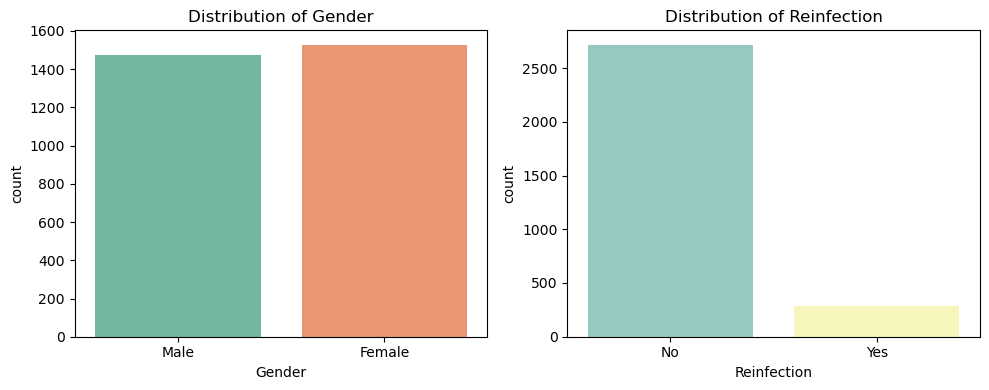

In [21]:
# Gender vs Infection

plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.countplot(data=df, x='Gender', palette='Set2')
plt.title('Distribution of Gender')

plt.subplot(1, 2, 2)
sns.countplot(data=covdf, x='Reinfection', palette='Set3')
plt.title('Distribution of Reinfection')

plt.tight_layout()
plt.show()

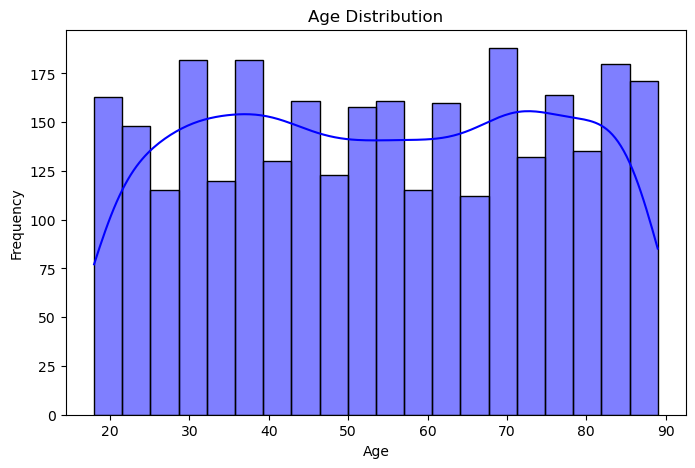

In [30]:
# Age Distribution

plt.figure(figsize=(8,5))
sns.histplot(data=covdf, x='Age', bins=20, kde=True, color='blue')
plt.title('Age Distribution')

plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

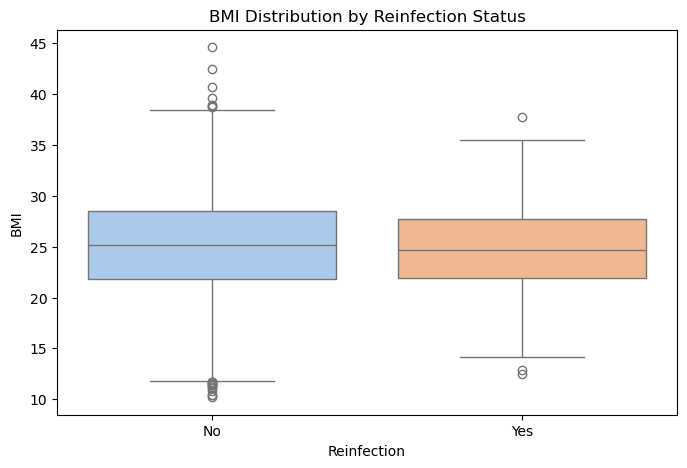

In [31]:
# BMI vs Reinfection status
plt.figure(figsize=(8, 5))
sns.boxplot(data=covdf, x='Reinfection', y='BMI', palette='pastel')
plt.title('BMI Distribution by Reinfection Status')
plt.xlabel('Reinfection')
plt.ylabel('BMI')
plt.show()

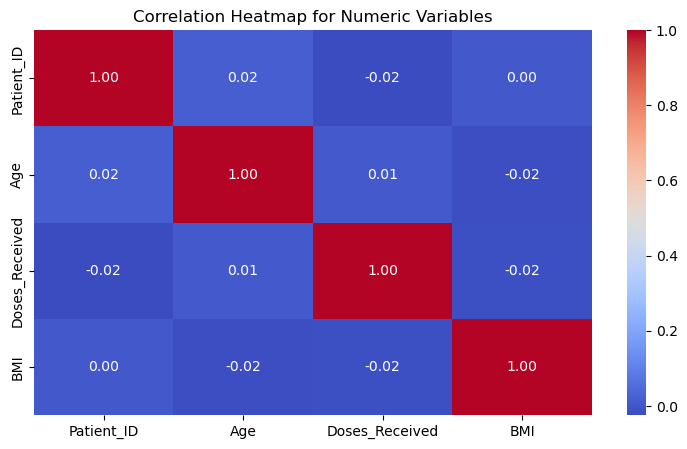

In [38]:
# correration heatmap

numeric_df = covdf.select_dtypes(include=[np.number])

if numeric_df.shape[1] >= 4:
    plt.figure(figsize=(9, 5))
    corr = numeric_df.corr()
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation Heatmap for Numeric Variables')
    plt.show()
else:
    print('Not enough numeric columns for a correlation heatmap.')

<Figure size 900x500 with 0 Axes>

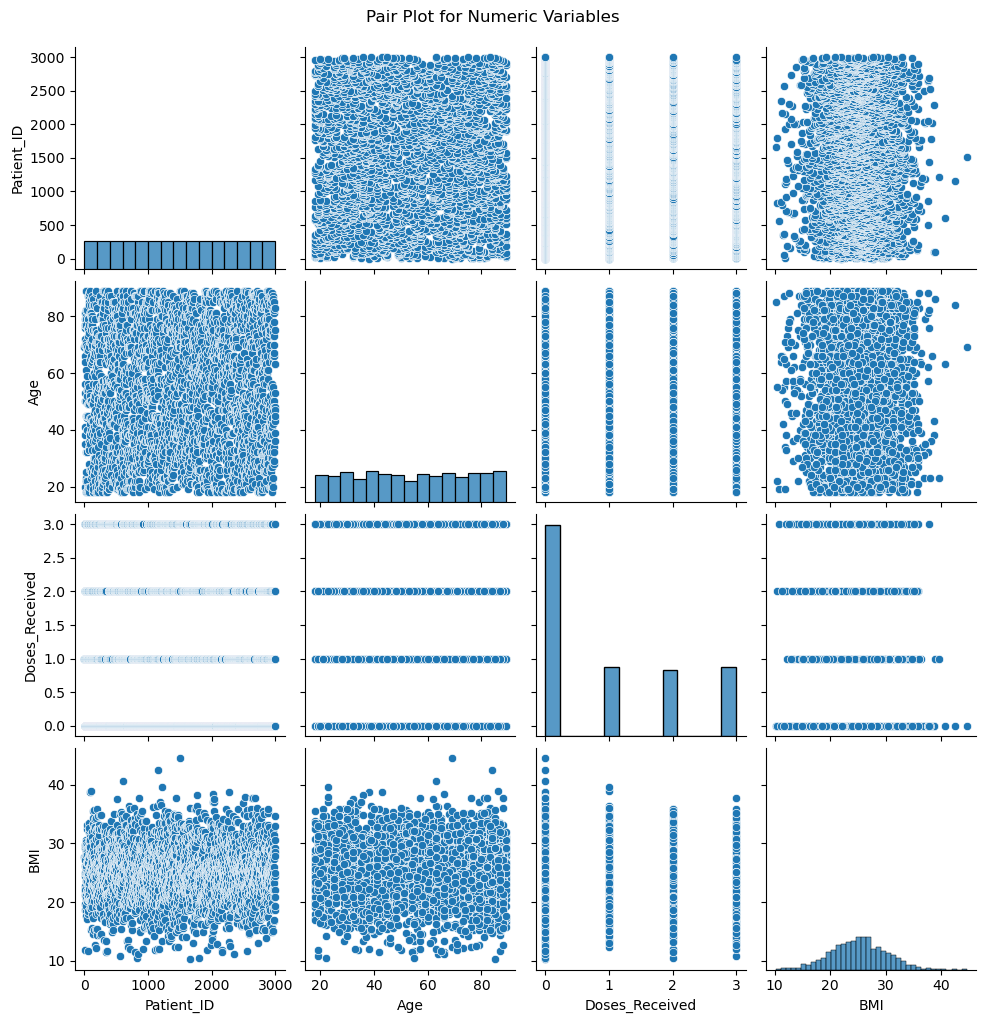

In [40]:
# pair plot for numeric data
if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(9, 5))
    sns.pairplot(numeric_df, diag_kind='hist')
    plt.suptitle('Pair Plot for Numeric Variables', y=1.02)
    plt.show()
else:
    print('Not enough numeric variables for a pair plot.')

**Modeling**

We develop a predictor to forecast whether patients might experience a COVID-19 reinfection. We will use logistic regression to predict the binary outcome in the 'Reinfection' column. 
The model will be evaluated with accuracy and a confusion matrix. Categorical variables are encoded appropriately for modeling. 
The code below constructs a pipeline to seamlessly perform preprocessing and classification.

In [41]:
# Copy dataframe to avoid unintended modifications
model_df = covdf.copy()

In [42]:
# For simplicity, we will predict Reinfection. Let's ensure it's binary (e.g., Yes/No)
model_df = model_df[model_df['Reinfection'].isin(['Yes', 'No'])]

# Create a binary label
le = LabelEncoder()
model_df['Reinfection_Label'] = le.fit_transform(model_df['Reinfection'])  # Yes=1, No=0


In [43]:
# Select features for the prediction model
# We choose a few features that might be predictors: Age, Gender, Preexisting_Condition, Vaccination_Status, Doses_Received, and BMI.
features = ['Age', 'Gender', 'Preexisting_Condition', 'Vaccination_Status', 'Doses_Received', 'BMI']
target = 'Reinfection_Label'

In [46]:
model_df.isnull().sum()

Patient_ID                    0
Age                           0
Gender                        0
Region                        0
Preexisting_Condition       469
Date_of_Infection             0
COVID_Strain                  0
Symptoms                      0
Severity                      0
Hospitalized                  0
Hospital_Admission_Date    2124
Hospital_Discharge_Date    2124
ICU_Admission                 0
Ventilator_Support            0
Recovered                     0
Date_of_Recovery           1492
Reinfection                   0
Date_of_Reinfection        2715
Vaccination_Status            0
Vaccine_Type               1809
Doses_Received                0
Date_of_Last_Dose          1528
Long_COVID_Symptoms        2780
Occupation                    0
Smoking_Status                0
BMI                           0
Reinfection_Label             0
dtype: int64

In [47]:
# Drop rows with missing values in the selected features
model_df = model_df.dropna(subset=features + [target])

In [48]:
model_df.head(5)

,Patient_ID,Age,Gender,Region,Preexisting_Condition,Date_of_Infection,COVID_Strain,Symptoms,Severity,Hospitalized,...,Date_of_Reinfection,Vaccination_Status,Vaccine_Type,Doses_Received,Date_of_Last_Dose,Long_COVID_Symptoms,Occupation,Smoking_Status,BMI,Reinfection_Label
0,1,69,Male,Hovedstaden,Obesity,2022-06-21,Delta,Mild,Moderate,Yes,...,NaT,Yes,NaN,1,2022-09-22,NaN,Healthcare,Never,27.7,0
1,2,38,Male,Sjælland,Asthma,2024-02-02,XBB.1.5,Mild,Moderate,No,...,NaT,No,NaN,0,NaT,NaN,Healthcare,Never,21.9,0
2,3,41,Female,Syddanmark,Hypertension,2023-05-28,Beta,Mild,High,Yes,...,NaT,Yes,Janssen,3,2024-05-14,NaN,Unemployed,Never,22.7,0
3,4,81,Female,Hovedstaden,Asthma,2023-08-13,Delta,Severe,High,No,...,2024-08-24,Yes,AstraZeneca,1,2024-10-31,NaN,Office Worker,Never,27.7,1
4,5,50,Female,Syddanmark,Cardiovascular,2023-03-10,Delta,Mild,High,No,...,NaT,Yes,NaN,2,2023-07-05,NaN,Student,Never,11.9,0


In [49]:
# Separate features and target
X = model_df[features]
y = model_df[target]

In [50]:
# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [51]:
# Preprocessing
#We will use one-hot encoding for categorical variables (Gender, Preexisting_Condition, Vaccination_Status) and pass numeric features through

categorical_features = ['Gender', 'Preexisting_Condition', 'Vaccination_Status']
numeric_features = ['Age', 'Doses_Received', 'BMI']

preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('num', 'passthrough', numeric_features)
    ]
)


In [52]:
# Builing a pipeline

pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [53]:
#fiting the pipeline
pipeline.fit(X_train, y_train)

#predict
y_pred = pipeline.predict(X_test)

#evaluation of the model
accuracy = accuracy_score(y_test, y_pred)
print('Accurecay of the Reinfection Predictor:', accuracy)

Accurecay of the Reinfection Predictor: 0.9013806706114399


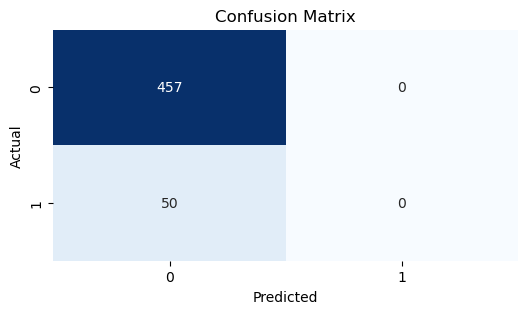

In [55]:
# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

**457 actually Positive Predicted as Positive** 

**50 actually Negative Predicted as Positive**

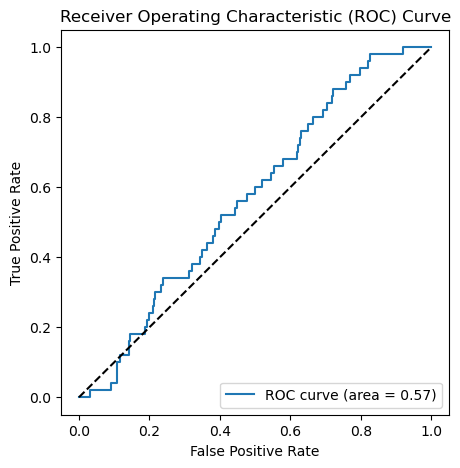

In [58]:
# ROC Curve

y_probs = pipeline.predict_proba(X_test)[:, 1]
fpr, tpr, thresholds = roc_curve(y_test, y_probs)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(5, 5))
plt.plot(fpr, tpr, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.show()

**Conclusion**

1. The Visual exploration highlighted patterns in demographics, health indicators and reinfection status.
2. The predictive basic model demonstrates the feasibility of forecasting reinfection likelihood using Logistic regression with an acceptable accuracy.

In [60]:
# needs more cleaning and different models to predict with more accuracy

